# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Vincent Valentino | 5054251016 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings("ignore")

In [65]:
mall = pd.read_csv('Mall_Customers.csv')
display(mall.shape)
display(mall.head())

(200, 5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [66]:
mall.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [67]:
mall.describe(include='all')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [68]:
dupes = mall.drop(columns='CustomerID')
print(dupes.duplicated().sum())
mall.isna().sum()

0


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

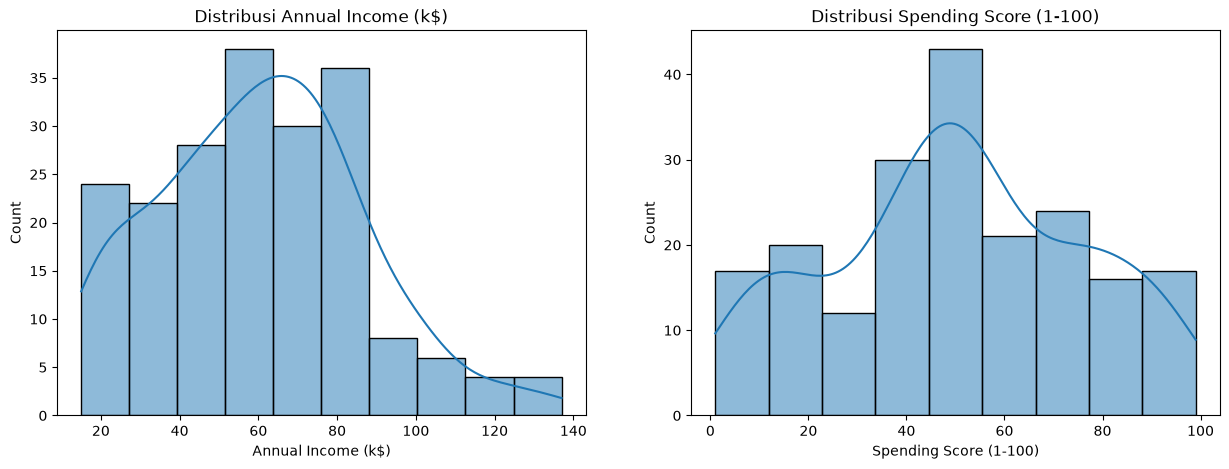

In [69]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
fig, axes = plt.subplots(1,2, figsize=(15,5))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sb.histplot(data=mall, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribusi {col}')

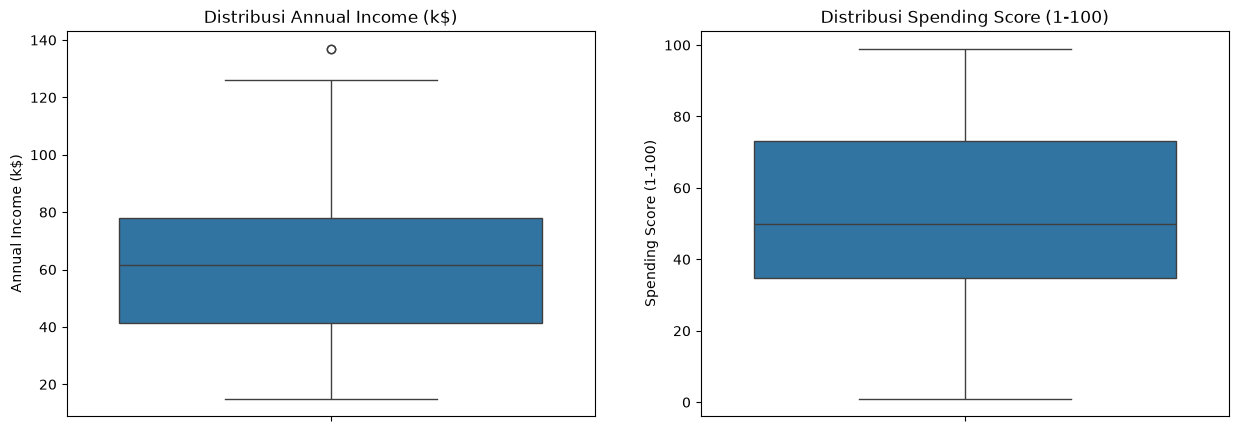

In [70]:
fig, axes = plt.subplots(1,2, figsize=(15,5))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sb.boxplot(data=mall, y=col, ax=ax)
    ax.set_title(f'Distribusi {col}')

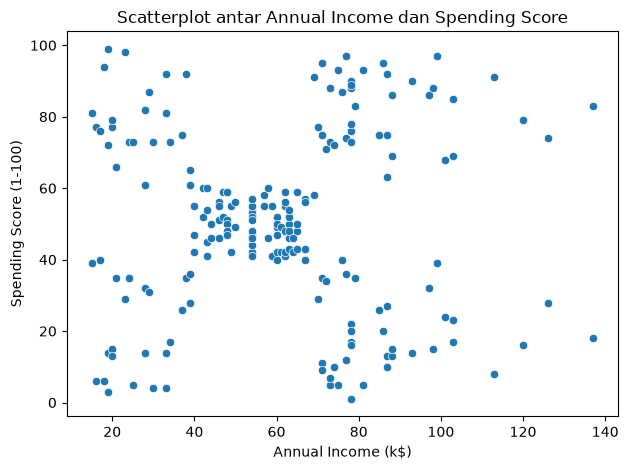

In [71]:
sb.scatterplot(data=mall, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title('Scatterplot antar Annual Income dan Spending Score')
plt.tight_layout()
plt.show()

## Pertanyaan EDA
**Apakah ada missing value atau baris duplikat?** Tidak ada

**Bagaimana rentang pendapatan dan spending score**

Annual Income berkisar sekitar 15 k$ hingga 137 k$.
* Mayoritas pelanggan berada pada rentang 40–80 k$.
* Terdapat nilai tinggi yang mendekati 140 k$, yang dapat dianggap sebagai outlier.

Spending Score berkisar sekitar 1 hingga 99.
* Sebaran cukup merata dari nilai rendah hingga tinggi.
* Tidak terlihat outlier yang signifikan pada boxplot.

**Apakah kedua fitur tampak memiliki kelompok yang terpisah?**

Ya, terdapat indikasi beberapa kelompok yang cukup jelas pada scatter plot Annual Income vs Spending Score.

Kelompok yang terlihat antara lain:
* Pendapatan rendah, spending tinggi (pojok kanan bawah)
* Pendapatan rendah, spending rendah (pojok kiri bawah)
* Pendapatan tinggi, spending tinggi (pojok kanan atas)
* Pendapatan tinggi, spending rendah (pojok kiri atas)
* Pendapatan dan spending sedang (tengah & yang paling jelas)

# 2. Preprocessing

In [72]:
x = mall[['Annual Income (k$)', 'Spending Score (1-100)']]

In [73]:
scaler = StandardScaler()
x_scaled = pd.DataFrame(scaler.fit_transform(x), columns=x.columns)
display(x_scaled.head())
display(x_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


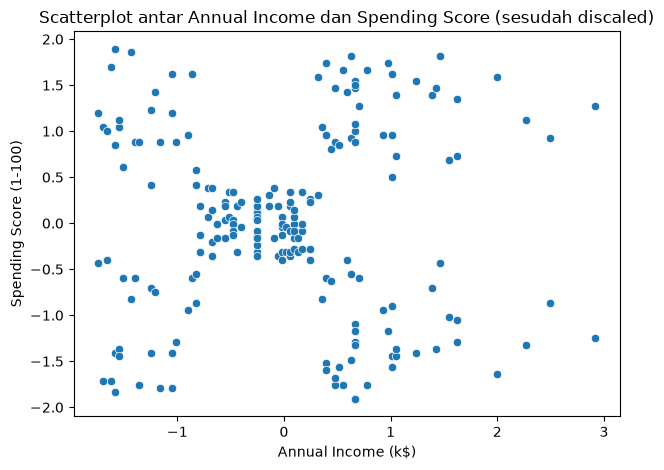

In [74]:
sb.scatterplot(data=x_scaled, x='Annual Income (k$)', y='Spending Score (1-100)')
plt.title('Scatterplot antar Annual Income dan Spending Score (sesudah discaled)')
plt.tight_layout()
plt.show()

Scaling sangat penting dikarenakan algoritma clustering seperti DBSCAN, Birch dan KMeans sangat bergantung terhadap perhitungan jarak. Tanpa scaling, fitur yang memiliki angka yang jauh lebih besar dibanding fitur-fitur lainnya dapat mendominasi pengukuran jarak dan menghasilkan bias

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Kedua fitur dipilih karena secara langsung menggambarkan karakteristik pelanggan yang relevan untuk segmentasi. `Annual Income` (k$) menunjukkan kemampuan finansial pelanggan, sedangkan `Spending Score (1-100)` menunjukkan tingkat pengeluaran atau perilaku konsumsi pelanggan.
`CustomerID` tidak digunakan karena hanya merupakan atribut identitas unik dan tidak berpengaruh sama sekali pada karakteristik pelanggan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [75]:
db = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = db.fit_predict(x_scaled)

In [76]:
clustered = x.copy()
clustered['cluster_DB'] = labels_dbscan
cluster_size = clustered['cluster_DB'].value_counts().sort_index()
display(cluster_size)

cluster_DB
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

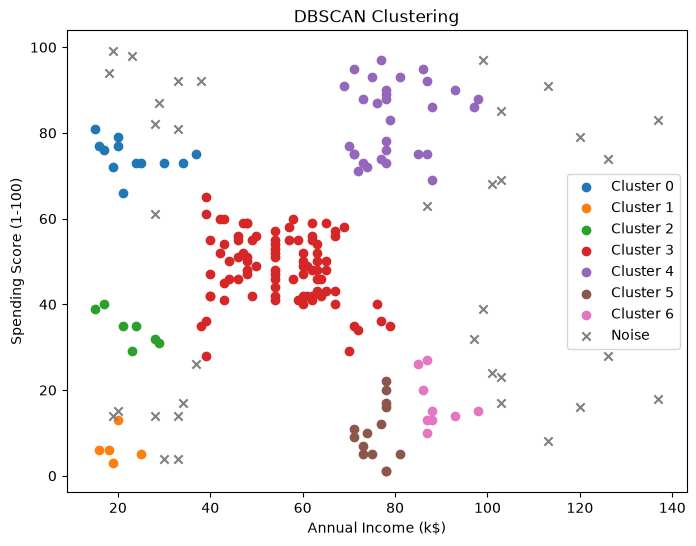

In [77]:
plt.figure(figsize=(8, 6))
for label in set(labels_dbscan):
    mask = labels_dbscan == label
    plt.scatter(x.loc[mask, 'Annual Income (k$)'], x.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}' if label != -1 else 'Noise', marker='x' if label == -1 else 'o')
plt.title('DBSCAN Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [78]:
results = []
for eps in [0.2, 0.3, 0.5, 0.7, 1.0]:
    for min_samples in [3, 5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(x_scaled)
        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)
        score = np.nan
        if n_clusters > 1:
            score = silhouette_score(x_scaled, labels)
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Jumlah Cluster': n_clusters,
            'Jumlah Noise': n_noise,
            'Silhouette Score': score
        })

results_df = pd.DataFrame(results)
display(results_df)

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Silhouette Score
0,0.2,3,13,44,0.230585
1,0.2,5,7,77,0.140579
2,0.2,10,1,129,NaN
3,0.3,3,9,14,0.413619
4,0.3,5,7,35,0.316141
5,0.3,10,4,88,0.140885
6,0.5,3,2,7,0.356602
7,0.5,5,2,8,0.350446
8,0.5,10,4,21,0.406405
9,0.7,3,1,0,NaN


### Analisis DBSCAN

#### 1. Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?

**Terhadap Noise:** Kenaikan `eps` (radius ketetanggaan) secara konsisten menurunkan jumlah noise. Radius pencarian yang semakin lebar membuat titik-titik di area pinggiran atau yang renggang lebih mudah terjangkau oleh core point lain, atau lebih mudah mengumpulkan tetangga untuk menjadi core point sendiri.

**Terhadap Jumlah Cluster:** Pada nilai `eps` yang sangat kecil, sebagian besar data terisolasi menjadi noise sehingga jumlah cluster sedikit/bahkan 0 dan ketika `eps` dinaikkan ke tingkat moderat, titik-titik mulai membentuk kelompok-kelompok terpisah (jumlah cluster bertambah). Namun, jika `eps` terus dinaikkan, cluster-cluster yang sebelumnya terpisah akan mulai saling menyatu (merging/chaining effect).

#### 2. Apa pengaruh `min_samples`?

`min_samples` menentukan jumlah minimum titik dalam radius `eps` agar suatu titik dikategorikan sebagai *core point*.

**Jika `min_samples` diperbesar:**
  - Syarat untuk menjadi *core point* semakin ketat karena membutuhkan lebih banyak tetangga.
  - Jumlah noise cenderung meningkat karena lebih banyak titik gagal memenuhi kriteria kepadatan.

**Jika `min_samples` diperkecil:**
  - Syarat menjadi lebih longgar sehingga lebih banyak titik dapat dikategorikan sebagai *core point*.
  - Jumlah noise cenderung berkurang karena lebih banyak titik dapat bergabung dengan cluster.

#### 3. Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?
- **Menghasilkan satu cluster besar (*under-clustering* / *chaining effect*):** Terjadi ketika nilai `eps` terlalu besar dan `min_samples` relatif kecil hingga sedang. Akibatnya, banyak titik saling terhubung dan membentuk satu cluster besar. Contohnya, `eps = 0.8` dengan `min_samples = 3` atau `5`.

- **Menghasilkan terlalu banyak noise (*over-filtering*):** Terjadi ketika nilai `eps` terlalu kecil dan/atau `min_samples` terlalu besar. Akibatnya, banyak titik tidak memenuhi kriteria kepadatan sehingga dikategorikan sebagai noise. Contohnya, `eps = 0.15` dengan `min_samples = 15` atau `eps = 0.20` dengan `min_samples = 15`.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [79]:
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(x_scaled)

In [80]:
clustered['cluster_BIRCH'] = labels_birch
cluster_size = clustered['cluster_BIRCH'].value_counts().sort_index()
display(cluster_size)

cluster_BIRCH
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

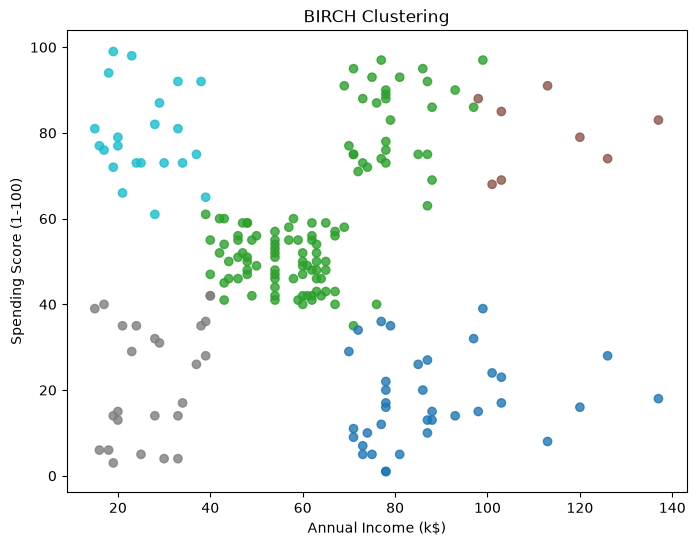

In [81]:
plt.figure(figsize=(8, 6))
plt.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels_birch, cmap='tab10', alpha=0.8)
plt.title('BIRCH Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [82]:
results = []

for threshold in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:
    model = Birch(threshold=threshold, n_clusters=5)
    labels = model.fit_predict(x_scaled)

    n_clusters = len(set(labels))
    score = np.nan

    if 1 < n_clusters < len(labels):
        score = silhouette_score(x_scaled, labels)

    results.append({
        'Threshold': threshold,
        'Jumlah Cluster': n_clusters,
        'Silhouette Score': score
    })

results_df = pd.DataFrame(results)
display(results_df)

,Threshold,Jumlah Cluster,Silhouette Score
0,0.1,5,0.553809
1,0.2,5,0.553809
2,0.3,5,0.478062
3,0.5,5,0.414450
4,0.7,5,0.420676
5,1.0,4,0.388557


### Analisis BIRCH

#### 1. Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?

Parameter `threshold` pada BIRCH menentukan radius maksimum toleransi dari sebuah Clustering Feature (CF) subcluster di leaf node CF-Tree. Ketika `threshold` diperbesar, batas radius satu subcluster menjadi lebih longgar, sehingga lebih banyak titik data yang dapat ditampung ke dalam satu CF subcluster yang sama. Akibatnya, jumlah subcluster awal pada leaf node akan semakin sedikit (data terkompresi lebih agresif).

#### 2. Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
| Aspek | DBSCAN | BIRCH |
|-|-|-|
| Identifikasi | Memiliki konsep noise. Titik yang tidak memenuhi syarat kepadatan (`min_samples` dalam radius `eps`) diberi label `-1`. | Tidak punya konsep noise. |
| Penanganan | Outlier dibiarkan terisolasi dan tidak dipaksa bergabung ke kelompok mana pun, sehingga cluster utama tetap bersih dan padat. | Outlier tetap dimasukkan ke CF subcluster terdekat, atau membentuk CF subcluster sendiri yang pada fase global clustering tetap dipaksa masuk ke salah satu cluster. |
| Dampak pada Hasil | Robust terhadap noise dan titik pencilan. | Outlier dapat menggeser centroid cluster utama, atau jika cukup terisolir, membentuk cluster kerdil tersendiri. |

#### 3. Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?
Ya, hasil BIRCH berubah secara signifikan, karena `n_clusters` yang ditentukan akan menjalankan algoritma global clustering (seperti Agglomerative Clustering) hingga menghasilkan n cluster, dibanding jika tidak ada `n_clusters` maka akan menjalankan algoritma sendiri.


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [83]:
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm.fit(x_scaled)
labels_gmm = gmm.predict(x_scaled)

In [84]:
clustered['cluster_GMM'] = labels_gmm
cluster_size = clustered['cluster_GMM'].value_counts().sort_index()
display(cluster_size)

cluster_GMM
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

In [85]:
proba = gmm.predict_proba(x_scaled)
proba_df = pd.DataFrame(proba, columns=[f'Cluster_{i}' for i in range(proba.shape[1])])
proba_df['Label'] = labels_gmm
proba_df['Max_Proba'] = proba.max(axis=1)
display(proba_df.head(10).round(3))

,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Label,Max_Proba
0,0.000,0.0,0.001,0.0,0.999,4,0.999
1,0.000,0.0,1.000,0.0,0.000,2,1.000
2,0.000,0.0,0.000,0.0,1.000,4,1.000
3,0.000,0.0,1.000,0.0,0.000,2,1.000
4,0.000,0.0,0.002,0.0,0.998,4,0.998
5,0.000,0.0,1.000,0.0,0.000,2,1.000
6,0.000,0.0,0.000,0.0,1.000,4,1.000
7,0.000,0.0,1.000,0.0,0.000,2,1.000
8,0.000,0.0,0.000,0.0,1.000,4,1.000
9,0.001,0.0,0.998,0.0,0.000,2,0.998


In [86]:
threshold_uncertain = 0.8 
uncertain = proba_df[proba_df['Max_Proba'] < threshold_uncertain]
display(uncertain.sort_values('Max_Proba').head(10).round(3))

,Cluster_0,Cluster_1,Cluster_2,Cluster_3,Cluster_4,Label,Max_Proba
124,0.497,0.0,0.000,0.503,0.000,3,0.503
48,0.611,0.0,0.000,0.000,0.388,0,0.611
49,0.611,0.0,0.000,0.000,0.388,0,0.611
27,0.279,0.0,0.675,0.000,0.046,2,0.675
160,0.772,0.0,0.000,0.228,0.000,0,0.772
55,0.796,0.0,0.000,0.000,0.204,0,0.796


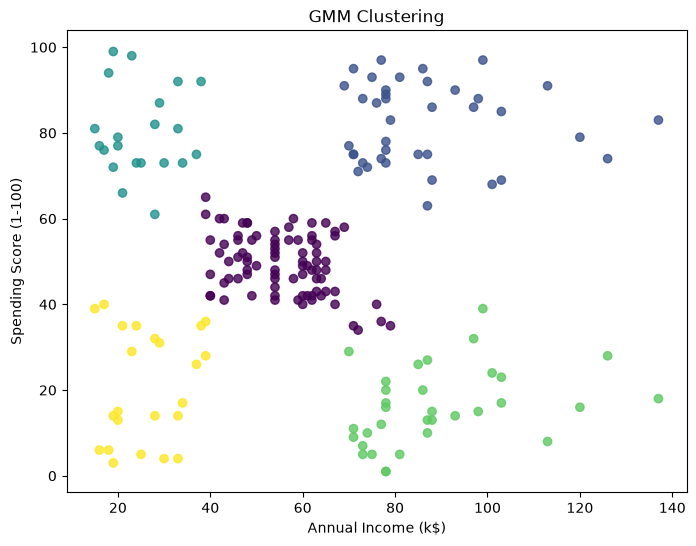

In [87]:
plt.figure(figsize=(8, 6))
plt.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels_gmm, cmap='viridis', alpha=0.8)
plt.title('GMM Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [88]:
results_gmm = []

for n in range(2, 9):
    model = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    labels = model.fit_predict(x_scaled)
    n_clusters = len(set(labels))
    score = np.nan

    if 1 < n_clusters < len(labels):
        score = silhouette_score(x_scaled, labels)

    results_gmm.append({
        'n_components': n,
        'Jumlah Cluster': n_clusters,
        'Silhouette Score': score,
        'BIC': model.bic(x_scaled),
        'Konvergen': model.converged_
    })

results_gmm_df = pd.DataFrame(results_gmm)
display(results_gmm_df.round(3))

,n_components,Jumlah Cluster,Silhouette Score,BIC,Konvergen
0,2,2,0.379,1153.905,True
1,3,3,0.430,1151.718,True
2,4,4,0.413,1103.790,True
3,5,5,0.554,1058.652,True
4,6,6,0.517,1074.683,True
5,7,7,0.509,1087.329,True
6,8,8,0.430,1102.371,True


### Analisis EM/GMM

#### 1. Apa arti probabilitas keanggotaan yang dihasilkan GMM?

Probabilitas keanggotaan menunjukkan seberapa besar kemungkinan suatu data termasuk ke dalam masing-masing cluster berdasarkan distribusi Gaussian yang dipelajari oleh model.

Berbeda dengan K-Means yang menetapkan setiap data hanya pada satu cluster, GMM menggunakan soft clustering, sehingga satu data dapat memiliki probabilitas keanggotaan pada beberapa cluster.

Contoh:
| Cluster | Probabilitas Keanggotaan |
|-|-|
| Cluster 1 | 0.75 (75%) |
| Cluster 2 | 0.20 (20%) |
| Cluster 3 | 0.05 (5%) |

Artinya, data tersebut memiliki kemungkinan terbesar untuk termasuk ke Cluster 1, tetapi masih memiliki kemungkinan menjadi bagian dari Cluster 2 atau 3.
#### 2. Apa yang terjadi ketika `n_components` diubah?
`n_components` menentukan jumlah distribusi Gaussian yang digunakan oleh GMM, yang umumnya merepresentasikan jumlah cluster.

- Nilai terlalu kecil: Beberapa kelompok data yang sebenarnya berbeda dapat digabung menjadi satu cluster sehingga pola data kurang terwakili.
- Nilai terlalu besar: Satu kelompok data dapat terpecah menjadi beberapa cluster kecil sehingga model berpotensi mengalami overfitting.
- Nilai yang sesuai: Model dapat merepresentasikan pola dan distribusi data dengan lebih baik.

Perubahan `n_components` juga memengaruhi probabilitas keanggotaan setiap data karena model mempelajari distribusi Gaussian yang berbeda.

#### 3. Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?

Karena GMM membutuhkan jumlah distribusi Gaussian yang akan dipelajari sebagai parameter awal model. Jumlah tersebut menentukan banyaknya distribusi Gaussian yang harus diestimasi, termasuk parameter mean, covariance, dan mixing coefficient. GMM kemudian menggunakan algoritma Expectation-Maximization (EM) untuk mengoptimalkan parameter distribusi berdasarkan jumlah komponen yang telah ditentukan.

#### 4. Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

Berdasarkan percobaan, iya. Nilai k = 5 menghasilkan Silhouette Score tertinggi (0.5537) sekaligus BIC terendah (1058.65). Keduanya sepakat bahwa 5 adalah jumlah cluster terbaik. Namun, sebenarnya tidak selalu karena pengukuran yang berbeda.
- Silhouette Score: Mengukur seberapa baik data berada dalam clusternya sendiri dibandingkan dengan cluster lain dan berbasis jarak geometris Euclidean.
- BIC (Bayesian Information Criterion): Mengevaluasi kualitas model berdasarkan kecocokan terhadap data dengan mempertimbangkan kompleksitas model dan berbasis teori probabilitas. 


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [89]:
def evaluate_clustering(X_scaled, labels, is_dbscan=False):
    if is_dbscan:
        mask = labels != -1
        eval_X = X_scaled[mask]
        eval_labels = labels[mask]
        n_clusters = len(set(eval_labels))
        n_noise = int(np.sum(labels == -1))
    else:
        eval_X = X_scaled
        eval_labels = labels
        n_clusters = len(set(eval_labels))
        n_noise = 0

    if 1 < n_clusters < len(eval_labels):
        sil = silhouette_score(eval_X, eval_labels)
        dbi = davies_bouldin_score(eval_X, eval_labels)
        chi = calinski_harabasz_score(eval_X, eval_labels)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    return {
        'Jumlah Cluster': n_clusters,
        'Jumlah Noise': n_noise,
        'Silhouette Score': sil,
        'Davies-Bouldin': dbi,
        'Calinski-Harabasz': chi,
    }

In [90]:
models = {
        'DBSCAN (eps=0.3, min_samples=5)': (labels_dbscan, True),
        'BIRCH (threshold=0.5, n_clusters=5)': (labels_birch, False),
        'GMM (n_components=5)': (labels_gmm, False),
}

results = []
for name, (lbls, is_db) in models.items():
    metrics = evaluate_clustering(x_scaled, lbls, is_dbscan=is_db)
    metrics['Model'] = name
    results.append(metrics)

eval_df = pd.DataFrame(results)[
    [
        'Model',
        'Jumlah Cluster',
        'Jumlah Noise',
        'Silhouette Score',
        'Davies-Bouldin',
        'Calinski-Harabasz',
    ]]
display(eval_df)

,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,"DBSCAN (eps=0.3, min_samples=5)",7,35,0.524328,0.579955,185.575811
1,"BIRCH (threshold=0.5, n_clusters=5)",5,0,0.414450,0.697938,125.948605
2,GMM (n_components=5),5,0,0.553689,0.576010,244.940197


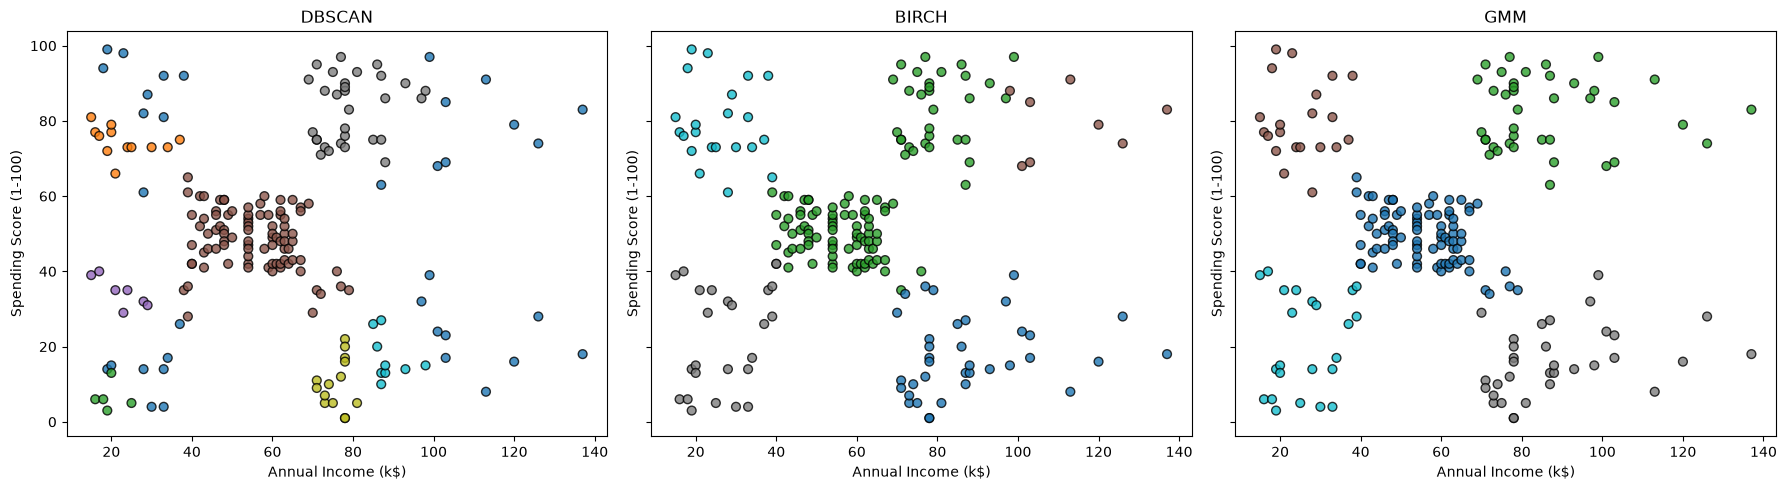

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
models = [(labels_dbscan, 'DBSCAN'), (labels_birch, 'BIRCH'), (labels_gmm, 'GMM')]
for ax, (labels, name) in zip(axes, models):
    ax.scatter(x['Annual Income (k$)'], x['Spending Score (1-100)'], c=labels, cmap='tab10', s=40, edgecolors='k', alpha=0.8)
    ax.set_title(f'{name}')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

In [92]:
def make_cluster_profile(df_features, labels, model_name):
    df_temp = df_features.copy()
    df_temp['Cluster'] = labels
    profile = (df_temp.groupby('Cluster').agg({'Annual Income (k$)': ['count', 'mean', 'median'], 'Spending Score (1-100)': ['mean', 'median'],}))
    print(f'=== Profil Cluster: {model_name} ===')
    display(profile)
    return profile

prof_db = make_cluster_profile(x, labels_dbscan, 'DBSCAN (eps=0.3, min_samples=5)')
prof_birch = make_cluster_profile(x, labels_birch, 'BIRCH (threshold=0.5, n_clusters=5)')
prof_gmm = make_cluster_profile(x, labels_gmm, 'GMM (n_components=5)')

=== Profil Cluster: DBSCAN (eps=0.3, min_samples=5) ===


Annual Income (k$)                   Spending Score (1-100)       
                     count       mean median                   mean median
Cluster                                                                   
-1                      35  70.600000   87.0              51.657143   61.0
 0                      12  23.166667   20.5              74.583333   74.0
 1                       5  19.600000   19.0               6.600000    6.0
 2                       7  22.428571   23.0              34.428571   35.0
 3                      88  55.227273   54.0              48.579545   49.0
 4                      30  79.533333   78.0              83.133333   86.0
 5                      14  75.928571   77.5              10.071429    9.5
 6                       9  88.777778   87.0              17.000000   15.0

=== Profil Cluster: BIRCH (threshold=0.5, n_clusters=5) ===


Annual Income (k$)                    Spending Score (1-100)       
                     count        mean median                   mean median
Cluster                                                                    
0                       36   87.750000   83.0              17.583333   16.0
1                      109   62.394495   62.0              59.256881   55.0
2                        8  112.625000  108.0              79.625000   81.0
3                       25   27.400000   28.0              22.600000   26.0
4                       22   25.727273   24.5              79.363636   77.0

=== Profil Cluster: GMM (n_components=5) ===


Annual Income (k$)                   Spending Score (1-100)       
                     count       mean median                   mean median
Cluster                                                                   
0                       84  55.642857   55.5              49.369048   49.5
1                       39  86.538462   79.0              82.128205   83.0
2                       21  25.095238   24.0              80.047619   77.0
3                       33  88.818182   86.0              16.000000   15.0
4                       23  26.304348   25.0              20.913043   17.0

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional | Ya |
| Dapat memberi label noise secara eksplisit? | Ya | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bebas | Cenderung bulat | Elips |
| Kelebihan | 1. Tahan terhadap outlier/noise karena dapat mengidentifikasi data yang tidak termasuk cluster.<br>2. Tidak perlu menentukan jumlah cluster di awal. | 1. Efisien dan cepat untuk dataset berukuran besar (*scalable*).<br>2. Mampu meringkas data menggunakan CF-Tree sehingga menghemat memori.<br> | 1. Menggunakan *soft clustering* sehingga menghasilkan probabilitas keanggotaan setiap data.<br>2. Fleksibel dalam memodelkan cluster dengan bentuk elips dan orientasi yang berbeda.<br> |
| Kekurangan | 1. Sensitif terhadap perbedaan densitas antar-cluster.<br>2. Sangat bergantung pada pemilihan parameter `eps` dan `min_samples`.<br> | 1. Sensitif terhadap urutan data masukan.<br>2. Hasil clustering dapat terpengaruh oleh outlier. | 1. Jumlah komponen (`n_components`) harus ditentukan sebelum pelatihan.<br>2. Sensitif terhadap inisialisasi dan dapat mengalami kesulitan ketika terdapat outlier ekstrem. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

#### 1. Mengapa fitur perlu di-scaling sebelum clustering?
Fitur perlu di-scaling karena algoritma clustering seperti DBSCAN, dan BIRCH menggunakan perhitungan jarak untuk menentukan kedekatan antar-data. GMM juga sensitif terhadap skala fitur karena menggunakan distribusi probabilitas dan estimasi kovarians.

#### 2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
- `eps` menentukan radius maksimum untuk menganggap dua titik sebagai tetangga. Semakin besar nilai eps, semakin banyak titik yang dapat saling terhubung sehingga cluster cenderung bergabung dan jumlah noise berkurang. Sebaliknya, nilai eps terlalu kecil dapat menghasilkan banyak noise karena banyak titik tidak memiliki cukup tetangga.
- `min_samples` menentukan jumlah minimum titik dalam radius eps agar suatu titik dianggap sebagai core point. Semakin besar nilainya, semakin sulit suatu titik memenuhi kriteria tersebut sehingga jumlah noise cenderung meningkat dan jumlah cluster dapat berkurang.

#### 3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
- `threshold` menentukan batas jarak maksimum dalam pembentukan subcluster pada CF-Tree. Nilai threshold yang lebih kecil menghasilkan lebih banyak subcluster karena data harus memiliki kedekatan yang lebih tinggi untuk digabungkan. Sebaliknya, nilai yang lebih besar memungkinkan lebih banyak data digabungkan sehingga jumlah subcluster cenderung berkurang.
- `n_clusters` menentukan jumlah cluster akhir yang ingin dihasilkan setelah proses pembentukan CF-Tree. Parameter ini mengatur pengelompokan subcluster menjadi sejumlah cluster yang ditentukan. Jika `n_clusters=None`, model menghasilkan puluhan subcluster mikro dan jika ditentukan (misal `n_clusters=5`), subcluster-subcluster mikro digabung secara hierarkis menjadi tepat 5 kelompok makro dengan batas keputusan yang jelas dan mudah diinterpretasikan.

#### 4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
Probabilitas keanggotaan menunjukkan seberapa besar kemungkinan suatu data termasuk ke dalam masing-masing cluster berdasarkan distribusi Gaussian yang dipelajari oleh model. Berbeda dengan K-Means yang menetapkan setiap data hanya pada satu cluster, GMM menggunakan soft clustering, sehingga satu data dapat memiliki probabilitas keanggotaan pada beberapa cluster.

Contoh:
| Cluster | Probabilitas Keanggotaan |
|-|-|
| Cluster 1 | 0.75 (75%) |
| Cluster 2 | 0.20 (20%) |
| Cluster 3 | 0.05 (5%) |

Artinya, data tersebut memiliki kemungkinan terbesar untuk termasuk ke Cluster 1, tetapi masih memiliki kemungkinan menjadi bagian dari Cluster 2 atau 3.

Dalam proses pelatihannya, GMM menggunakan algoritma Expectation-Maximization (EM) yang terdiri dari dua tahap:
1. Expectation (E-step) menghitung probabilitas keanggotaan setiap data terhadap masing-masing distribusi Gaussian berdasarkan parameter model saat ini.
2. Maximization (M-step) memperbarui parameter model, yaitu mean, covariance, dan mixing coefficient berdasarkan probabilitas keanggotaan yang telah dihitung.
Kedua tahap tersebut dilakukan secara berulang hingga model mencapai kondisi konvergen. Dengan demikian, GMM dapat menyesuaikan distribusi Gaussian berdasarkan pola data.

#### 5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
GMM, karena hasil clustering yang dihasilkan cukup sesuai dengan ekspektasi dan pola yang saya amati ketika pertama kali melihat dataset. Pembagian cluster yang dihasilkan mampu merepresentasikan karakteristik pelanggan berdasarkan pendapatan dan spending score dengan cukup baik.

#### 6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
Ya, ketiga metrik evaluasi internal secara konsisten menempatkan GMM sebagai algoritma terbaik:
- GMM ($n=5$):
  - *Silhouette Score* tertinggi: 0.5537 (menunjukkan kepadatan dan pemisahan antar cluster sangat baik).
  - *Davies-Bouldin Index* terendah: 0.5760 (menunjukkan rasio jarak dalam cluster terhadap jarak antar cluster paling optimal).
  - *Calinski-Harabasz Score* tertinggi: 244.94 (rasio dispersi antar-cluster terhadap dalam-cluster paling tinggi).
- DBSCAN: Memiliki nilai *Silhouette Score* 0.5243 hanya jika mengevaluasi titik non-noise. Namun jika seluruh data dievaluasi, skornya turun drastis ke 0.3161 akibat penalti jarak dari 35 titik noise.
- BIRCH: Menghasilkan metrik lebih rendah (*Silhouette* = 0.4145, DBI = 0.6979) karena bentuk cluster tengah yang terlalu besar dan kompresi awal pada *CF-Tree* mengaburkan batas pemisahan.

#### 7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.


Berdasarkan hasil pemodelan terbaik (GMM dengan 5 komponen), profil tiap cluster adalah:

| Cluster | Jumlah Anggota | Median Income | Median Spending | Karakteristik & Nama Deskriptif |
|-|-|-|-|-|
| 0 | 84 (42.0%) | \$55.5k | 49.5 | **Regular Customers:** Segmen terbesar, pendapatan menengah dengan kebiasaan belanja yang stabil dan terukur. |
| 1 | 39 (19.5%) | \$79.0k | 83.0 | **VIP Customers:** Daya beli tinggi dan pengeluaran tinggi|
| 2 | 21 (10.5%) | \$24.0k | 77.0 | **High-Spenders:** Pendapatan rendah namun pengeluaran sangat tinggi |
| 3 | 33 (16.5%) | \$86.0k | 15.0 | **Frugal:** Pendapatan tinggi namun sangat cermat dan hemat |
| 4 | 23 (11.5%) | \$25.0k | 17.0 | **Broke mfs** Pendapatan rendah dan pengeluaran rendah |

#### 8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?
1. Keterbatasan Dua Fitur (`Annual Income` dan `Spending Score`): Mengabaikan variabel demografis penting seperti `Age` dan `Gender`, padahal kelompok usia dan jenis kelamin yang berbeda dapat memiliki kebiasaan serta pola konsumsi yang berbeda
2. Keterbatasan Dataset Kecil (200 Baris Data): Kurang representatif yang dimana 200 observasi tidak mencerminkan keragaman populasi nyata pelanggan mall secara menyeluruh.

# 8. Kesimpulan dan Saran

#### 1. Algoritma yang Paling Berguna
GMM-EM adalah algoritma yang paling unggul dan berguna untuk dataset ini. GMM mampu menangkap struktur alami 5 segmen pelanggan secara simetris, menghasilkan nilai metrik evaluasi internal terbaik (*Silhouette* 0.5537, DBI 0.5760, CH 244.94).

### 2. Parameter yang Dipilih dan Alasannya
- **GMM:** `n_components = 5`, `covariance_type = 'full'`, `random_state = 42`.
  - Alasan: Nilai k=5 memberikan keseimbangan optimal antara kecocokan probabilitas dan kompleksitas model, dibuktikan dengan nilai **BIC terendah (1058.65)** dan **Silhouette Score tertinggi (0.5537)**.
- **DBSCAN:** `eps = 0.3`, `min_samples = 5`.
  - Alasan: Menghindari chaining effect.
- **BIRCH:** `threshold = 0.5`, `n_clusters = 5`.
  - Alasan: Mencegah terjadinya *subcluster deficiency* (`ConvergenceWarning` yang terjadi pada `threshold = 1.0`) dan mempartisi data ke dalam 5 kelompok 

### 3. Perbedaan Utama Ketiga Algoritma yang Dipelajari
- DBSCAN: Mengelompokkan data berdasarkan kepadatan titik dan mampu mendeteksi noise.
- BIRCH: Mengelompokkan data menggunakan struktur CF-Tree sehingga lebih efisien untuk dataset besar.
- GMM: Mengelompokkan data berdasarkan distribusi probabilitas Gaussian (soft clustering).

### 4. Saran Eksperimen Lanjutan
1. Memasukkan fitur `Age` dan `Gender` ke dalam ruang fitur clustering menggunakan teknik reduksi dimensi seperti PCA
2. Menguji algoritma HDBSCAN (*Hierarchical DBSCAN*) yang dapat menyesuaikan variasi kepadatan data secara otomatis tanpa memerlukan parameter `eps` tunggal yang statis.
3. Menambahkan data lebih banyak untuk melihat efektivitas BIRCH

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)